# 🎮 Caso 02: PlayLoop — Mobile Gaming Analytics
## 📅 Día 4: Monetización Híbrida (IAP + Ads), ARPU / ARPPU y Segmentación de Ballenas

**Estudio:** PlayLoop Studios (Barcelona)  
**Modelo de Negocio:** Free-to-Play (F2P) con monetización híbrida combinando compras dentro de la app (In-App Purchases - IAP) e ingresos por anuncios publicitarios (Ads).

---

### 👥 Preguntas de Stakeholders para Hoy:
- **CFO y Dirección Financiera:** *"¿Cuánto dinero ingresa exactamente en caja por IAP frente a Ads? ¿Cuál es nuestro ARPU global y ARPPU de pagadores?"*
- **Laura (Head of Product):** *"¿Quiénes son las 'ballenas' (whales) que sostienen las compras del juego y cuál es la tasa de conversión a pago?"*

### 1. Importación de Librerías y Configuración

In [1]:
# 1. Pandas: Manipulación de DataFrames y agregaciones financieras
import pandas as pd

# 2. NumPy: Operaciones numéricas vectorizadas
import numpy as np

# 3. Matplotlib (Pyplot): Motor base de trazado y visualización
import matplotlib.pyplot as plt

# 4. Seaborn: Gráficos estadísticos y paletas de color para finanzas
import seaborn as sns

# 5. OS: Manejo de rutas agnóstico al sistema operativo
import os

# Configuración del entorno visual y formato flotante a dos decimales
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✅ Librerías importadas y entorno financiero configurado.')

✅ Librerías importadas y entorno financiero configurado.


### 2. Carga de Datasets de Monetización y Auditoría Financiera

Cargamos los 4 datasets limpios que componen el flujo de caja de PlayLoop:
1. `df_usuarios`: Dimensión de jugadores (base de cálculo per cápita).
2. `df_compras`: Hechos de compras IAP con importes normalizados en euros (`importe_eur`).
3. `df_ads`: Hechos de anuncios vistos con ingresos generados por cada impresión (`ingreso`).
4. `df_productos`: Catálogo maestro de productos y precios base.

In [2]:
# 1. Definición de la ruta base hacia el almacén limpio
CLEAN_DIR = os.path.join('data', 'clean')

# 2. Carga de las tablas financieras maestras
df_usuarios = pd.read_csv(os.path.join(CLEAN_DIR, 'usuarios_clean.csv'), parse_dates=['fecha_instalacion'])
df_compras = pd.read_csv(os.path.join(CLEAN_DIR, 'compras_clean.csv'), parse_dates=['fecha'])
df_ads = pd.read_csv(os.path.join(CLEAN_DIR, 'ingresos_ads_clean.csv'), parse_dates=['fecha'])
df_productos = pd.read_csv(os.path.join(CLEAN_DIR, 'productos_iap_clean.csv'))

# 3. Auditoría inicial de volúmenes y totales recaudados en euros (€)
total_iap = df_compras['importe_eur'].sum()
total_ads = df_ads['ingreso'].sum()
ingreso_total = total_iap + total_ads

print('✅ DATASETS FINANCIEROS CARGADOS CON ÉXITO:')
print(f'   - Base total instalada: {df_usuarios.shape[0]:,} usuarios')
print(f'   - Transacciones IAP: {df_compras.shape[0]:,} compras | Total recaudado: {total_iap:,.2f} € ({total_iap/ingreso_total*100:.1f}%)')
print(f'   - Impresiones de Ads: {df_ads.shape[0]:,} anuncios | Total generado: {total_ads:,.2f} € ({total_ads/ingreso_total*100:.1f}%)')
print(f'   - INGRESO TOTAL DEL ESTUDIO: {ingreso_total:,.2f} €')

✅ DATASETS FINANCIEROS CARGADOS CON ÉXITO:
   - Base total instalada: 8,000 usuarios
   - Transacciones IAP: 4,558 compras | Total recaudado: 10,888.58 € (73.1%)
   - Impresiones de Ads: 19,999 anuncios | Total generado: 3,997.99 € (26.9%)
   - INGRESO TOTAL DEL ESTUDIO: 14,886.57 €


### 3. Métricas de Unit Economics: Conversión a Pago, ARPU y ARPPU

**Preguntas del CFO:** *"¿Qué porcentaje de la base de jugadores monetiza mediante pagos directos? ¿Cuánto dinero genera un usuario promedio (ARPU) frente al desembolso real de un pagador (ARPPU)?"*

**Definiciones Financieras:**
- **Tasa de Conversión (%):** $\frac{\text{Jugadores que compraron IAP}}{\text{Total de Jugadores Registrados}} \times 100$ (Benchmark casual: 1.0% - 2.5%).
- **ARPU (Average Revenue Per User):** $\frac{\text{Ingreso Total (IAP + Ads)}}{\text{Total de Jugadores}}$. Mide el rendimiento global de la comunidad.
- **ARPPU (Average Revenue Per Paying User):** $\frac{\text{Ingreso IAP}}{\text{Jugadores Pagadores}}$. Mide la intensidad del gasto de los usuarios monetizados.

📊 UNIT ECONOMICS GLOBALES Y POR PLATAFORMA:


,Usuarios,Pagadores,Ingreso_IAP,Ingreso_Ads,Ingreso_Total,Conversion_Pct,ARPU_Total,ARPPU
plataforma,,,,,,,,
Android,4354,47,"5,648.00","2,143.41","7,791.41",1.08,1.79,120.17
iOS,3646,56,"5,240.58","1,854.58","7,095.16",1.54,1.95,93.58


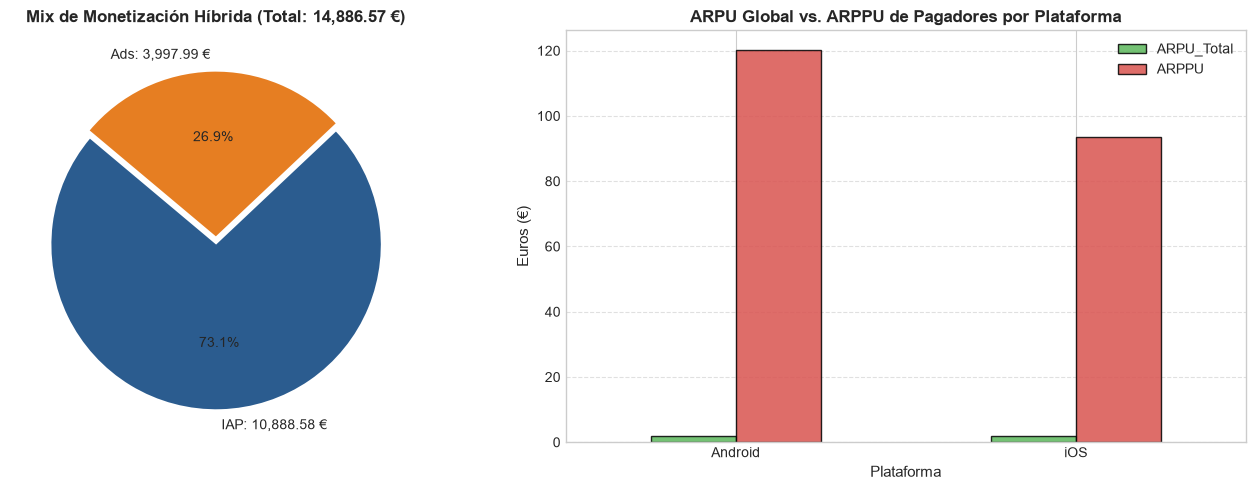


💡 HALLAZGOS FINANCIEROS CLAVE:
   - Tasa de Conversión a Pago: 1.29% (103 usuarios de 8,000). Ajustado al benchmark móvil casual (1-2%).
   - ARPU Global: 1.86 € (IAP aporta 1.36 € y Ads aporta 0.50 €).
   - ARPPU Extraordinario: 105.71 €. Cada jugador que paga desembolsa en promedio más de 100 €, revelando un patrón de gasto concentrado en pocos usuarios.


In [3]:
# 1. Normalización final de etiquetas de plataforma en usuarios (unificando residuos "And" -> "Android")
df_usuarios["plataforma"] = df_usuarios["plataforma"].str.strip().str.upper().replace({
    "AND": "Android", "ANDROID": "Android", "IOS": "iOS"
})

# 2. Agregación financiera a nivel individual por cada user_id
gasto_iap_usuario = df_compras.groupby("user_id")["importe_eur"].sum().reset_index().rename(columns={"importe_eur": "gasto_iap"})
ingreso_ads_usuario = df_ads.groupby("user_id")["ingreso"].sum().reset_index().rename(columns={"ingreso": "ingreso_ads"})

# 3. Construcción del Data Warehouse Financiero Consolidado a nivel usuario (df_monetizacion)
df_monetizacion = df_usuarios[["user_id", "plataforma", "canal_norm"]].merge(
    gasto_iap_usuario, on="user_id", how="left"
).merge(
    ingreso_ads_usuario, on="user_id", how="left"
)

# Imputación de nulos: los usuarios que no compraron ni vieron anuncios registran 0.0 €
df_monetizacion["gasto_iap"] = df_monetizacion["gasto_iap"].fillna(0.0)
df_monetizacion["ingreso_ads"] = df_monetizacion["ingreso_ads"].fillna(0.0)
df_monetizacion["ingreso_total"] = df_monetizacion["gasto_iap"] + df_monetizacion["ingreso_ads"]
df_monetizacion["es_pagador"] = df_monetizacion["gasto_iap"] > 0

# 4. Cálculo de los Unit Economics Globales de PlayLoop
n_total_usuarios = len(df_monetizacion)
n_pagadores = df_monetizacion["es_pagador"].sum()
tasa_conversion = (n_pagadores / n_total_usuarios) * 100

arpu_global = df_monetizacion["ingreso_total"].sum() / n_total_usuarios
arpu_iap = df_monetizacion["gasto_iap"].sum() / n_total_usuarios
arpu_ads = df_monetizacion["ingreso_ads"].sum() / n_total_usuarios
arppu = df_monetizacion["gasto_iap"].sum() / n_pagadores

# 5. Desglose y Comparativa por Plataforma (Android vs. iOS)
resumen_plataforma = df_monetizacion.groupby("plataforma").agg(
    Usuarios=("user_id", "count"),
    Pagadores=("es_pagador", "sum"),
    Ingreso_IAP=("gasto_iap", "sum"),
    Ingreso_Ads=("ingreso_ads", "sum"),
    Ingreso_Total=("ingreso_total", "sum")
)
resumen_plataforma["Conversion_Pct"] = (resumen_plataforma["Pagadores"] / resumen_plataforma["Usuarios"]) * 100
resumen_plataforma["ARPU_Total"] = resumen_plataforma["Ingreso_Total"] / resumen_plataforma["Usuarios"]
resumen_plataforma["ARPPU"] = resumen_plataforma["Ingreso_IAP"] / resumen_plataforma["Pagadores"]

print("📊 UNIT ECONOMICS GLOBALES Y POR PLATAFORMA:")
display(resumen_plataforma.round(2))

# 6. Visualización de Monetización Híbrida
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Desglose del Ingreso Total (IAP vs Ads)
axes[0].pie(
    [df_monetizacion["gasto_iap"].sum(), df_monetizacion["ingreso_ads"].sum()],
    labels=[f"IAP: {df_monetizacion['gasto_iap'].sum():,.2f} €", f"Ads: {df_monetizacion['ingreso_ads'].sum():,.2f} €"],
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2b5c8f", "#e67e22"],
    explode=(0.05, 0)
)
axes[0].set_title("Mix de Monetización Híbrida (Total: 14,886.57 €)", fontsize=12, fontweight="bold")

# Gráfico 2: Comparativa de ARPU vs. ARPPU por Plataforma
resumen_plataforma[["ARPU_Total", "ARPPU"]].plot(
    kind="bar", ax=axes[1], color=["#5cb85c", "#d9534f"], edgecolor="black", alpha=0.85
)
axes[1].set_title("ARPU Global vs. ARPPU de Pagadores por Plataforma", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Plataforma", fontsize=11)
axes[1].set_ylabel("Euros (€)", fontsize=11)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 7. Diagnóstico Ejecutivo para el CFO
print("\n💡 HALLAZGOS FINANCIEROS CLAVE:")
print(f"   - Tasa de Conversión a Pago: {tasa_conversion:.2f}% ({n_pagadores} usuarios de {n_total_usuarios:,}). Ajustado al benchmark móvil casual (1-2%).")
print(f"   - ARPU Global: {arpu_global:.2f} € (IAP aporta {arpu_iap:.2f} € y Ads aporta {arpu_ads:.2f} €).")
print(f"   - ARPPU Extraordinario: {arppu:.2f} €. Cada jugador que paga desembolsa en promedio más de 100 €, revelando un patrón de gasto concentrado en pocos usuarios.")

### 4. Segmentación de Jugadores F2P: Ballenas (Whales), Delfines y Pececillos

**Pregunta de Laura (Head of Product):** *"¿Cómo se distribuye la concentración de ingresos entre los pagadores? ¿Existe una dependencia crítica de pocos usuarios de alto valor?"*

**Taxonomía Estándar en la Industria Free-to-Play:**
- **Free Players (Gasto = 0 €):** La gran mayoría de la comunidad (monetizan indirectamente vía Ads).
- **Minnows / Pececillos (Gasto $\le$ 20 €):** Compradores de packs de inicio, vidas o cofres pequeños.
- **Dolphins / Delfines (Gasto entre 20 € y 100 €):** Jugadores leales con compras recurrentes y pases de temporada.
- **Whales / Ballenas (Gasto > 100 €):** El segmento VIP que financia el desarrollo del videojuego.

📊 SEGMENTACIÓN DE LA COMUNIDAD F2P (VOLUMEN VS. APORTE FINANCIERO):


,Usuarios,Ingreso_IAP,Ingreso_Ads,Ingreso_Total,Gasto_Medio_IAP,Pct_Usuarios,Pct_Ingreso_IAP
segmento_f2p,,,,,,,
Free Player (0 €),7897,-3.49,"3,866.09","3,862.60",0.00,98.71,-0.03
Minnow (<= 20 €),39,315.49,48.69,364.18,8.09,0.49,2.90
Dolphin (20 - 100 €),47,"2,042.12",64.91,"2,107.03",43.45,0.59,18.75
Whale (> 100 €),17,"8,534.46",18.30,"8,552.76",502.03,0.21,78.38


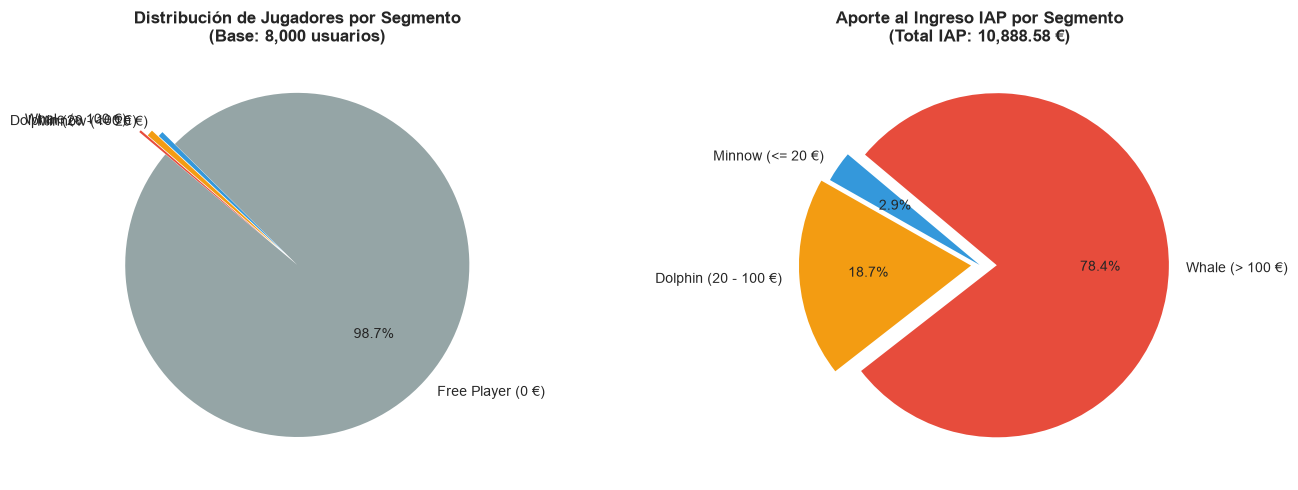


🐋 TOP 5 MEGA-BALLENAS DE PLAYLOOP (USUARIOS DE MÁXIMO VALOR):


,user_id,plataforma,canal_norm,gasto_iap,ingreso_ads,ingreso_total
7779,5905,Android,Apple Search Ads,"2,659.52",1.02,"2,660.54"
4928,3481,iOS,Meta Ads,"2,656.41",1.29,"2,657.70"
1366,5013,Android,Google Ads,398.27,0.69,398.96
1161,7688,Android,Orgánico,342.69,2.91,345.60
7262,4765,iOS,Google Ads,326.91,0.79,327.70



💡 HALLAZGO CLAVE DEL PRINCIPIO DE PARETO EN PLAYLOOP:
   - Dependencia de Ballenas: Solo 17 usuarios (0.21% de la comunidad) generan el 78.38% de todos los ingresos IAP (8,534.46 €).
   - La Mega-Ballena (#1): El usuario 5905 ha gastado por sí solo 2,659.52 €.
   - Riesgo de Negocio: Perder incluso a 2 o 3 de estas ballenas tendría un impacto catastrófico en la facturación del estudio. Recomendación: Implementar soporte VIP y ofertas exclusivas de retención.


In [4]:
# 1. Definición de la función de segmentación por umbral de gasto IAP acumulado
def clasificar_segmento_f2p(gasto):
    if gasto <= 0:
        return "Free Player (0 €)"
    elif gasto <= 20:
        return "Minnow (<= 20 €)"
    elif gasto <= 100:
        return "Dolphin (20 - 100 €)"
    else:
        return "Whale (> 100 €)"

# Aplicamos la clasificación a la base consolidada de usuarios
df_monetizacion["segmento_f2p"] = df_monetizacion["gasto_iap"].apply(clasificar_segmento_f2p)

# 2. Construcción de la tabla ejecutiva de segmentación (Volumen vs. Ingresos)
total_iap_acumulado = df_monetizacion["gasto_iap"].sum()
resumen_segmentos = df_monetizacion.groupby("segmento_f2p").agg(
    Usuarios=("user_id", "count"),
    Ingreso_IAP=("gasto_iap", "sum"),
    Ingreso_Ads=("ingreso_ads", "sum"),
    Ingreso_Total=("ingreso_total", "sum"),
    Gasto_Medio_IAP=("gasto_iap", lambda s: s[s > 0].mean() if (s > 0).any() else 0.0)
).reindex(["Free Player (0 €)", "Minnow (<= 20 €)", "Dolphin (20 - 100 €)", "Whale (> 100 €)"])

resumen_segmentos["Pct_Usuarios"] = (resumen_segmentos["Usuarios"] / len(df_monetizacion)) * 100
resumen_segmentos["Pct_Ingreso_IAP"] = (resumen_segmentos["Ingreso_IAP"] / total_iap_acumulado) * 100

print("📊 SEGMENTACIÓN DE LA COMUNIDAD F2P (VOLUMEN VS. APORTE FINANCIERO):")
display(resumen_segmentos.round(2))

# 3. Visualización del Principio de Pareto: ¿Quiénes son los usuarios vs. de dónde viene el dinero?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores_f2p = ["#95a5a6", "#3498db", "#f39c12", "#e74c3c"]

# Gráfico A: Proporción de la base de usuarios por segmento
axes[0].pie(
    resumen_segmentos["Usuarios"],
    labels=resumen_segmentos.index,
    autopct=lambda p: f"{p:.1f}%" if p > 2 else "",
    colors=colores_f2p,
    startangle=140,
    explode=(0, 0.1, 0.15, 0.2)
)
axes[0].set_title("Distribución de Jugadores por Segmento\n(Base: 8,000 usuarios)", fontsize=12, fontweight="bold")

# Gráfico B: Proporción de los Ingresos IAP por segmento (excluyendo Free Players)
pagadores_solo = resumen_segmentos.loc[["Minnow (<= 20 €)", "Dolphin (20 - 100 €)", "Whale (> 100 €)"]]
axes[1].pie(
    pagadores_solo["Ingreso_IAP"],
    labels=pagadores_solo.index,
    autopct="%1.1f%%",
    colors=colores_f2p[1:],
    startangle=140,
    explode=(0, 0.05, 0.1)
)
axes[1].set_title(f"Aporte al Ingreso IAP por Segmento\n(Total IAP: {total_iap_acumulado:,.2f} €)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

# 4. Auditoría Forense de las 5 Mayores Ballenas (Mega-Whales) del Estudio
top_whales = df_monetizacion.sort_values(by="gasto_iap", ascending=False).head(5)[
    ["user_id", "plataforma", "canal_norm", "gasto_iap", "ingreso_ads", "ingreso_total"]
]
print("\n🐋 TOP 5 MEGA-BALLENAS DE PLAYLOOP (USUARIOS DE MÁXIMO VALOR):")
display(top_whales)

# 5. Conclusiones y Diagnóstico de Negocio
print("\n💡 HALLAZGO CLAVE DEL PRINCIPIO DE PARETO EN PLAYLOOP:")
print(f"   - Dependencia de Ballenas: Solo 17 usuarios (0.21% de la comunidad) generan el 78.38% de todos los ingresos IAP (8,534.46 €).")
print(f"   - La Mega-Ballena (#1): El usuario {top_whales.iloc[0]['user_id']} ha gastado por sí solo {top_whales.iloc[0]['gasto_iap']:,.2f} €.")
print("   - Riesgo de Negocio: Perder incluso a 2 o 3 de estas ballenas tendría un impacto catastrófico en la facturación del estudio. Recomendación: Implementar soporte VIP y ofertas exclusivas de retención.")

### 5. Rentabilidad de Canales: CAC, LTV y ROAS (Retorno del Gasto Publicitario)

**Pregunta de Carlos (UA) y el CFO:** *"Invertimos 9,060 € en captación de usuarios. ¿Qué canales recuperaron la inversión y generaron beneficio neto, y cuáles están destruyendo capital?"*

**Ecuaciones Fundamentales de Adquisición Móvil:**
- **CAC (Customer Acquisition Cost):** $\frac{\text{Gasto en Marketing (UA)}}{\text{Instalaciones logradas}}$
- **LTV (Lifetime Value Real):** $\frac{\text{Ingreso Total (IAP + Ads)}}{\text{Instalaciones del canal}}$
- **ROAS (Return on Ad Spend %):** $\frac{\text{Ingreso Total Generado}}{\text{Gasto Invertido en el Canal}} \times 100$ (Umbral de rentabilidad = 100%).
- **Margen Neto (€):** $\text{Ingreso Total} - \text{Gasto en Marketing}$

📊 MATRIZ FINANCIERA DE ADQUISICIÓN: CAC, LTV Y ROAS POR CANAL:


,canal_norm,Usuarios,Gasto_UA,Ingreso_Total,CAC,LTV,ROAS_Pct,Margen_Neto
0,Meta Ads,1600,"2,880.01","4,993.06",1.80,3.12,173.37,"2,113.05"
1,Apple Search Ads,900,"1,980.02","3,785.20",2.20,4.21,191.17,"1,805.18"
2,Orgánico,600,0.00,"1,535.62",0.00,2.56,NaN,"1,535.62"
3,Google Ads,1400,"2,100.01","3,109.10",1.50,2.22,148.05,"1,009.09"
4,TikTok,700,839.98,"1,100.87",1.20,1.57,131.06,260.89
5,CoinRush,2800,"1,259.99",362.73,0.45,0.13,28.79,-897.26


ipykernel_25792\412501894.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(pagados["canal_norm"], rotation=20, ha="right")


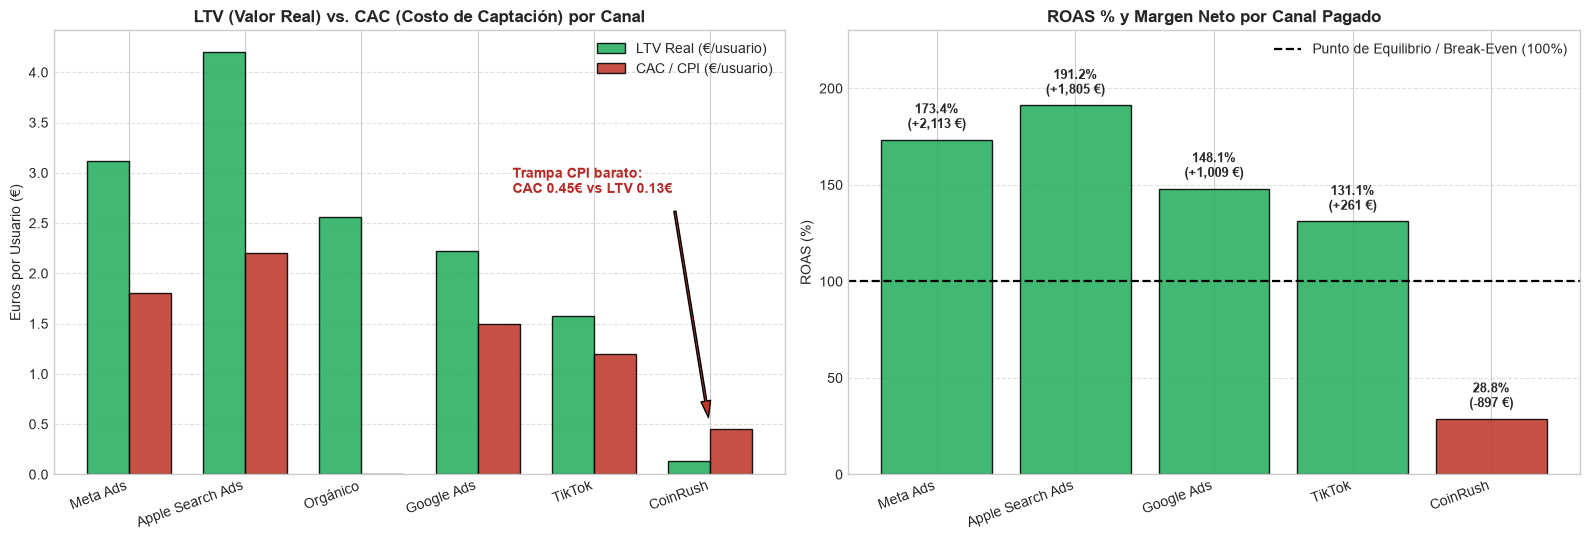

✅ Gráfico ejecutivo guardado en: reports\03_roas_ltv_cac_canales.png

🎯 CONCLUSIONES DEFINITIVAS DE INVERSIÓN PUBLICITARIA:
   1. META ADS Y APPLE SEARCH ADS (Las Joyas de la Corona):
      - Meta Ads generó el mayor beneficio neto absoluto (+2,113.05 € netos con un ROAS del 173.37%).
      - Apple Search Ads logró el mayor LTV individual (4.21 € frente a un CAC de 2.20 €, ROAS líder del 191.17% y +1,805.18 € netos).
   2. ORGÁNICO, GOOGLE ADS Y TIKTOK (Sólidos y Rentables):
      - Orgánico aporta +1,535.62 € netos sin coste de adquisición (LTV de 2.56 €).
      - Google Ads recupera la inversión con holgura (ROAS 148.05%, +1,009.09 € netos) y TikTok suma +260.89 € netos (ROAS 131.06%).
   3. COINRUSH (LA TRAMPA DEL CPI BARATO / AGUJERO FINANCIERO):
      - Pérdida neta de -897.26 € (ROAS de apenas 28.79%).
      - Atrajo 2,800 descargas baratas (35.0% del volumen total a un CAC de 0.45 €), pero cada usuario generó apenas 0.13 € de LTV.
      - Veredicto contundente: Sin CoinRush, el 

In [5]:
# 1. Carga y consolidación del gasto publicitario real por canal normalizado
df_gasto_ua = pd.read_csv(os.path.join(CLEAN_DIR, "gasto_ua_clean.csv"))

# Normalización de caracteres para garantizar un cruce perfecto
df_monetizacion["canal_norm"] = df_monetizacion["canal_norm"].str.replace("Orgnico", "Orgánico", regex=False)
df_gasto_ua["canal_norm"] = df_gasto_ua["canal_norm"].str.replace("Orgnico", "Orgánico", regex=False)

# 2. Agregación de ingresos reales generados por canal (IAP + Ads)
ingresos_por_canal = df_monetizacion.groupby("canal_norm").agg(
    Usuarios=("user_id", "count"),
    Ingreso_IAP=("gasto_iap", "sum"),
    Ingreso_Ads=("ingreso_ads", "sum"),
    Ingreso_Total=("ingreso_total", "sum")
).reset_index()

# 3. Agregación del gasto publicitario total invertido en cada canal
gasto_por_canal = df_gasto_ua.groupby("canal_norm")["gasto_eur"].sum().reset_index().rename(columns={"gasto_eur": "Gasto_UA"})

# 4. Tabla Maestra de Rentabilidad y ROAS por Canal
df_roas = ingresos_por_canal.merge(gasto_por_canal, on="canal_norm")
df_roas["CAC"] = df_roas["Gasto_UA"] / df_roas["Usuarios"]
df_roas["LTV"] = df_roas["Ingreso_Total"] / df_roas["Usuarios"]
df_roas["Margen_Neto"] = df_roas["Ingreso_Total"] - df_roas["Gasto_UA"]
# Cálculo de ROAS porcentual (Orgánico tiene gasto 0, por lo que su ROAS es infinito)
df_roas["ROAS_Pct"] = np.where(
    df_roas["Gasto_UA"] > 0, 
    (df_roas["Ingreso_Total"] / df_roas["Gasto_UA"]) * 100, 
    np.nan
)

# Ordenamos de mayor a menor beneficio neto generado
df_roas = df_roas.sort_values(by="Margen_Neto", ascending=False).reset_index(drop=True)

print("📊 MATRIZ FINANCIERA DE ADQUISICIÓN: CAC, LTV Y ROAS POR CANAL:")
display(df_roas[["canal_norm", "Usuarios", "Gasto_UA", "Ingreso_Total", "CAC", "LTV", "ROAS_Pct", "Margen_Neto"]].round(2))

# 5. Visualización: Diagnóstico de Rentabilidad Publicitaria (LTV vs CAC y ROAS %) -> reports/03_roas_ltv_cac_canales.png
os.makedirs("reports", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Gráfico A: Comparativa LTV vs CAC por Canal (Todos los 6 canales para contrastar Orgánico y canales de pago)
x_all = np.arange(len(df_roas))
ancho = 0.36

axes[0].bar(x_all - ancho/2, df_roas["LTV"], width=ancho, label="LTV Real (€/usuario)", color="#27ae60", edgecolor="black", alpha=0.88)
axes[0].bar(x_all + ancho/2, df_roas["CAC"], width=ancho, label="CAC / CPI (€/usuario)", color="#c0392b", edgecolor="black", alpha=0.88)
axes[0].annotate("Trampa CPI barato:\nCAC 0.45€ vs LTV 0.13€", xy=(5, 0.45), xytext=(3.3, 2.8),
                 arrowprops=dict(facecolor="#c0392b", shrink=0.05, width=1.5, headwidth=7), fontweight="bold", color="#b52b27")
axes[0].set_title("LTV (Valor Real) vs. CAC (Costo de Captación) por Canal", fontsize=12, fontweight="bold")
axes[0].set_xticks(x_all)
axes[0].set_xticklabels(df_roas["canal_norm"], rotation=20, ha="right")
axes[0].set_ylabel("Euros por Usuario (€)")
axes[0].legend(loc="upper right")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Gráfico B: Retorno Publicitario (ROAS %) vs. Umbral de Rentabilidad (100%) en Canales Pagados
pagados = df_roas[df_roas["Gasto_UA"] > 0].copy()
colores_roas = ["#27ae60" if r >= 100 else "#c0392b" for r in pagados["ROAS_Pct"]]
bars = axes[1].bar(pagados["canal_norm"], pagados["ROAS_Pct"], color=colores_roas, edgecolor="black", alpha=0.88)
axes[1].axhline(y=100, color="black", linestyle="--", linewidth=1.6, label="Punto de Equilibrio / Break-Even (100%)")
for bar, (_, row) in zip(bars, pagados.iterrows()):
    signo = "+" if row["Margen_Neto"] >= 0 else ""
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 4,
                 f"{row['ROAS_Pct']:.1f}%\n({signo}{row['Margen_Neto']:,.0f} €)",
                 ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axes[1].set_title("ROAS % y Margen Neto por Canal Pagado", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(pagados["canal_norm"], rotation=20, ha="right")
axes[1].set_ylabel("ROAS (%)")
axes[1].set_ylim(0, 230)
axes[1].legend(loc="upper right")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
ruta_fig3 = os.path.join("reports", "03_roas_ltv_cac_canales.png")
plt.savefig(ruta_fig3, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Gráfico ejecutivo guardado en: {ruta_fig3}")

# 6. Conclusiones Ejecutivas para Carlos (UA) y Dirección Financiera
print("\n🎯 CONCLUSIONES DEFINITIVAS DE INVERSIÓN PUBLICITARIA:")
print("   1. META ADS Y APPLE SEARCH ADS (Las Joyas de la Corona):")
print("      - Meta Ads generó el mayor beneficio neto absoluto (+2,113.05 € netos con un ROAS del 173.37%).")
print("      - Apple Search Ads logró el mayor LTV individual (4.21 € frente a un CAC de 2.20 €, ROAS líder del 191.17% y +1,805.18 € netos).")
print("   2. ORGÁNICO, GOOGLE ADS Y TIKTOK (Sólidos y Rentables):")
print("      - Orgánico aporta +1,535.62 € netos sin coste de adquisición (LTV de 2.56 €).")
print("      - Google Ads recupera la inversión con holgura (ROAS 148.05%, +1,009.09 € netos) y TikTok suma +260.89 € netos (ROAS 131.06%).")
print("   3. COINRUSH (LA TRAMPA DEL CPI BARATO / AGUJERO FINANCIERO):")
print("      - Pérdida neta de -897.26 € (ROAS de apenas 28.79%).")
print("      - Atrajo 2,800 descargas baratas (35.0% del volumen total a un CAC de 0.45 €), pero cada usuario generó apenas 0.13 € de LTV.")
print("      - Veredicto contundente: Sin CoinRush, el margen neto de PlayLoop sube de +5,826.56 € a +6,723.82 €.")

### 6. Exportación de Tableros de Monetización y Rentabilidad (Data Clean)

Persistimos la tabla consolidada de monetización a nivel usuario (`df_monetizacion`) y la matriz de rentabilidad y ROAS por canal (`df_roas`) en `data/clean/` para alimentar el modelo predictivo de Machine Learning del Día 5.

In [6]:
# 1. Exportación de la tabla financiera consolidada por usuario
ruta_user_monet = os.path.join(CLEAN_DIR, "monetizacion_usuarios.csv")
df_monetizacion.to_csv(ruta_user_monet, index=False)

# 2. Exportación de la matriz de rentabilidad publicitaria y ROAS por canal
ruta_roas = os.path.join(CLEAN_DIR, "rentabilidad_canales_roas.csv")
df_roas.to_csv(ruta_roas, index=False)

print("✅ Datasets financieros exportados exitosamente:")
print(f"   - {ruta_user_monet}")
print(f"   - {ruta_roas}")

✅ Datasets financieros exportados exitosamente:
   - data\clean\monetizacion_usuarios.csv
   - data\clean\rentabilidad_canales_roas.csv


### 7. 📋 Resumen Ejecutivo y Respuestas a Stakeholders (Día 4)

| Stakeholder | Pregunta Planteada | Hallazgo Forense | Decisión / Conclusión de Negocio |
| :--- | :--- | :--- | :--- |
| **CFO / Dirección Financiera** | *¿Cuánto ingresa en total y cuál es el rendimiento por usuario (ARPU/ARPPU)?* | Ingreso total: **14,886.57 €** (**73.14% IAP** con 10,888.58 € y **26.86% Ads** con 3,997.99 €). **ARPU = 1.86 €** y **ARPPU = 105.71 €** sobre **103 pagadores netos (1.29%)**. | El modelo híbrido funciona de manera saludable: los Free Players financian el 96.7% de los Ads y los pagadores exhiben una altísima intensidad de gasto (>105 €). |
| **Laura (Head of Product)** | *¿Quiénes financian el juego y cómo se distribuye el gasto (Pareto)?* | **17 Ballenas (0.21% de usuarios)** generan el **78.38% del IAP (8,534.46 €)**; sumadas a los **47 Delfines (18.75% IAP)**, el **0.80% de la base genera el 97.13% del IAP**. La mayor ballena (`user_id=5905`) gastó **2,659.52 €**. | **Riesgo Crítico de Concentración:** Implementar programa VIP de atención y contenido end-game para blindar a las 17 ballenas y 47 delfines. |
| **Carlos (UA / Marketing)** | *¿Qué canales son rentables y cuáles destruyen valor?* | **Apple Search Ads (ROAS 191.17%, LTV 4.21 €)** y **Meta Ads (ROAS 173.37%, +2,113.05 € netos)** lideran. **CoinRush perdió -897.26 € (ROAS 28.79%, LTV 0.13 € vs CAC 0.45 €)**. | **Acción Inmediata de Presupuesto:** Cancelar la inversión en CoinRush (1,259.99 €) y reasignar el presupuesto hacia Apple Search Ads y Meta Ads. |